# Car Price Prediction: EDA & Machine Learning Integration
**A portfolio project: predicting used-car prices and deploying the model as a Streamlit web app**

## Table of Contents
1. Introduction
2. Business Problem
3. Project Objectives
4. Importing the Required Libraries
5. Understanding the Dataset
6. Initial Data Examination
7. Data Cleaning
8. Data Analysis (EDA)
9. Feature Selection
10. Train/Test Split
11. Model Selection and Training
12. Model Evaluation
13. Model Deployment with Web App
14. Conclusion
15. Recommendations
16. References

# 1. Introduction

Machine learning and data analysis have become essential tools for predictive analytics across many industries. Within the automotive sector, the ability to estimate the selling price of a used vehicle supports dealerships, online marketplaces, buyers and sellers in making fairer and more consistent pricing decisions.

This project carries a dataset of 15,411 used vehicles through the complete data science lifecycle: understanding and cleaning the data, exploring it, engineering and selecting features, training and tuning multiple machine learning models, evaluating and comparing their performance, and finally deploying the best-performing model as an interactive web application built with Streamlit.

# 2. Business Problem

## Objective
The objective of this project is to develop a machine learning model capable of predicting the selling price of a used vehicle based on its characteristics, and to make that model accessible through an interactive web application.

The selling price of a used vehicle is shaped by many characteristics that interact in complex ways, which makes consistent, fair pricing difficult to achieve by judgement alone. The factors that plausibly influence selling price in this dataset include:

- Vehicle age
- Kilometres driven (odometer reading)
- Mileage (fuel efficiency, km/l)
- Engine capacity
- Maximum power
- Number of seats
- Fuel type
- Transmission type
- Seller type
- Brand and model

Because these variables interact in complex ways, the relationships between them and the selling price must first be understood before a reliable predictive model can be built. This project explores the dataset, assesses and cleans its quality, examines how each characteristic relates to selling price, selects the features that carry the strongest signal, trains and evaluates multiple models, and deploys the best one, supporting fairer pricing and better decision-making for dealerships, online marketplaces and consumers.

# 3. Project Objectives

The objectives of this project are to:

- Load and understand the dataset.
- Explore the characteristics of the available variables.
- Assess the quality of the data.
- Perform data cleaning, including handling missing values, duplicates and outliers.
- Conduct exploratory data analysis (EDA) to examine distributions and trends.
- Apply feature engineering and preprocessing, including transformation, standardisation and encoding.
- Select the features most strongly associated with the selling price.
- Train and hyperparameter-tune three machine learning models (Ridge Regression, Random Forest and Gradient Boosting).
- Evaluate and compare model performance using appropriate regression metrics.
- Deploy the best-performing model as an interactive Streamlit web application.

# 4. Importing the Required Libraries

## Objective
This project spans data preparation, model training and deployment, so we import everything up front: pandas/NumPy/Matplotlib/Seaborn for EDA, scikit-learn for preprocessing, modelling and evaluation, and joblib for saving the trained model so the Streamlit app can load it later.

## Why is this step important?
Rather than writing complex algorithms from scratch, we import libraries that already provide this functionality reliably. Importing everything at once, rather than piecemeal, keeps the rest of the notebook uninterrupted.

In [1]:
# ---- Data handling & visualisation ----
import pandas as pd                # reads/cleans/analyses tabular data as a DataFrame
import numpy as np                 # numerical computation, arrays, log/exp transforms
import matplotlib.pyplot as plt    # base plotting library (histograms, boxplots, scatter)
import seaborn as sns              # statistical plots built on Matplotlib (heatmaps, styled bar charts)

import warnings
warnings.filterwarnings("ignore")  # suppress non-critical library warnings so output stays readable
%matplotlib inline                 # render plots directly below each cell, not in a separate window
sns.set_style("whitegrid")         # apply a consistent, light grid background to every plot

# ---- Preprocessing, feature selection, modelling, evaluation ----
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
# train_test_split   : splits data into training and test sets
# GridSearchCV        : exhaustively tries every combination in a parameter grid, with cross-validation
# RandomizedSearchCV  : samples a fixed number of random combinations instead of trying all of them
from sklearn.preprocessing import StandardScaler   # rescales numeric features to mean 0, std 1
from sklearn.feature_selection import SelectKBest, f_regression
# SelectKBest   : keeps only the k highest-scoring features
# f_regression  : scores each feature by the strength of its linear relationship with the target
from sklearn.linear_model import Ridge   # linear regression with L2 (shrinkage) regularisation
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
# RandomForestRegressor      : an ensemble of decision trees trained on random subsets (bagging)
# GradientBoostingRegressor  : trees trained sequentially, each correcting the previous ones' errors
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
# mean_squared_error   : average squared prediction error (its square root gives RMSE)
# mean_absolute_error  : average absolute prediction error, in the target's own units
# r2_score             : proportion of variance in the target explained by the model (1.0 = perfect)

# ---- Saving artifacts for the web app ----
import joblib   # efficiently saves/loads Python objects (here: the trained model bundle) to/from disk
import os       # used to create the output folder the model bundle is saved into


## Interpretation
The required libraries have been imported successfully and are now available throughout the notebook. pandas and NumPy handle data loading and numerical computation, Matplotlib and Seaborn generate the visualisations used throughout, and scikit-learn provides preprocessing tools, three regression algorithms, hyperparameter search utilities and evaluation metrics. joblib will be used at the end of the notebook to save the trained model and its preprocessing pipeline so the Streamlit app can load them later.

# 5. Understanding the Dataset

## Objective
Load the dataset into a DataFrame, confirm its size, and view the actual records to form initial impressions before any cleaning or analysis begins.

In [2]:
# read_csv() reads a comma-separated (CSV) file and returns a pandas DataFrame.
# The file path is passed as a string. The CSV sits in the same folder as
# this notebook, so only the file name is needed. The result is stored in
# df, which represents the dataset throughout the rest of the notebook.
df = pd.read_csv("car_price_dataset.csv")

# .shape returns a (rows, columns) tuple, confirming the file loaded and
# showing how many vehicle records and attributes the dataset contains.
print("Shape:", df.shape)

# .head() returns the first 5 rows; .tail() returns the last 5. Viewing both
# gives an initial look at the data and helps confirm it stays consistent
# from the start of the file to the end. display() renders both tables in
# a single cell (a plain df.head() followed by df.tail() would only show
# the last one).
display(df.head())
display(df.tail())


Shape: (15411, 14)


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
15406,19537,Hyundai i10,Hyundai,i10,9,10723,Dealer,Petrol,Manual,19.81,1086,68.05,5,250000
15407,19540,Maruti Ertiga,Maruti,Ertiga,2,18000,Dealer,Petrol,Manual,17.50,1373,91.10,7,925000
15408,19541,Skoda Rapid,Skoda,Rapid,6,67000,Dealer,Diesel,Manual,21.14,1498,103.52,5,425000
15409,19542,Mahindra XUV500,Mahindra,XUV500,5,3800000,Dealer,Diesel,Manual,16.00,2179,140.00,7,1225000
15410,19543,Honda City,Honda,City,2,13000,Dealer,Petrol,Automatic,18.00,1497,117.60,5,1200000


## Interpretation
The dataset holds 15,411 used-vehicle records across 14 columns: numeric measurements (vehicle_age, km_driven, mileage, engine, max_power, seats), categorical descriptors (brand, model, seller_type, fuel_type, transmission_type), and two non-informative fields (Unnamed: 0, a leftover index, and car_name, which just concatenates brand and model). The tail already exposes a data-quality issue worth carrying forward: one vehicle records 3,800,000 km driven, well beyond a plausible odometer reading. This will be addressed in Section 7 (Data Cleaning).

# 6. Initial Data Examination

## Objective
Examine the dataset's structure (non-null counts, data types, and whether any columns need type conversion), then generate summary statistics for the numeric and categorical columns.

In [3]:
# .info() gives a concise technical summary of the DataFrame: the total
# number of rows, and for each column its name, its count of non-null
# (non-missing) values, and its data type. It also reports the memory the
# DataFrame currently uses, which the next cell will reduce.
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  str    
 2   brand              15411 non-null  str    
 3   model              15411 non-null  str    
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  str    
 7   fuel_type          15411 non-null  str    
 8   transmission_type  15411 non-null  str    
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), str(6)
memory usage: 1.6 MB


In [4]:
# Memory footprint before any conversion
mem_before = df.memory_usage(deep=True).sum()
print(f"Memory before: {mem_before/1024:.1f} KB")

# The nominal categorical columns are stored as generic 'object' (plain text),
# even though each holds only a handful of repeating values. Casting them to
# pandas' 'category' dtype stores each unique value once and references it by
# a small integer code: same information, far less memory, and signals to
# downstream tools (plotting, groupby, encoding) that these are categorical.
cat_cols = ["brand", "model", "seller_type", "fuel_type", "transmission_type"]
df[cat_cols] = df[cat_cols].astype("category")

mem_after = df.memory_usage(deep=True).sum()
print(f"Memory after:  {mem_after/1024:.1f} KB")
print(f"Reduction: {(1 - mem_after/mem_before)*100:.1f}%")

Memory before: 6055.7 KB
Memory after:  1974.4 KB
Reduction: 67.4%


In [5]:
# .describe() computes summary statistics for the numeric columns: count,
# mean, standard deviation, minimum, the 25th/50th/75th percentiles
# (quartiles), and the maximum. .round(2) limits the output to 2 decimals.
display(df.describe().round(2))

# include=["object", "category"] switches .describe() to the non-numeric
# columns, reporting count, number of unique categories, the most frequent
# category (top), and how many times it occurs (freq). Both dtypes are
# listed because the previous cell already converted some columns to
# pandas' 'category' dtype.
display(df.describe(include=["object", "category"]))


,Unnamed: 0,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.00,15411.00,15411.00,15411.00,15411.00,15411.00,15411.00,15411.00
mean,9811.86,6.04,55616.48,19.70,1486.06,100.59,5.33,774971.12
std,5643.42,3.01,51618.55,4.17,521.11,42.97,0.81,894128.36
min,0.00,0.00,100.00,4.00,793.00,38.40,0.00,40000.00
25%,4906.50,4.00,30000.00,17.00,1197.00,74.00,5.00,385000.00
50%,9872.00,6.00,50000.00,19.67,1248.00,88.50,5.00,556000.00
75%,14668.50,8.00,70000.00,22.70,1582.00,117.30,5.00,825000.00
max,19543.00,29.00,3800000.00,33.54,6592.00,626.00,9.00,39500000.00


,car_name,brand,model,seller_type,fuel_type,transmission_type
count,15411,15411,15411,15411,15411,15411
unique,121,32,120,3,5,2
top,Hyundai i20,Maruti,i20,Dealer,Petrol,Manual
freq,906,4992,906,9539,7643,12225


## Interpretation
No column has missing values, and all 14 dtypes already match what they represent, so the only conversion needed was cosmetic-but-meaningful: casting the five nominal columns (brand, model, seller_type, fuel_type, transmission_type) from generic object/text to pandas' category dtype. Because each of these columns repeats a small set of values across 15,411 rows, storing each value once and referencing it by code cut total memory usage by roughly two-thirds, a real efficiency gain even on a dataset this small.

The summary statistics describe a typical vehicle as roughly 6 years old, driven about 50,000 km, returning 19.7 km/l, with a 1,248 cc engine, 88.5 bhp, 5 seats, and a median price near ₹556,000. Several columns are visibly right-skewed (mean > median for km_driven, engine, max_power and especially selling_price), and the same two problems already visible in the raw view reappear numerically: km_driven maxes out at 3,800,000 and seats has a minimum of 0, both physically impossible, both to be handled in the next section. The categorical summary confirms the market is dominated by Maruti, petrol, manual, dealer-sold vehicles.

# 7. Data Cleaning

## Objective
Remove non-informative columns, confirm and handle missing values, remove duplicate records, and detect and treat outliers using both graphical (boxplot) and non-graphical (IQR) methods.

## Why this order matters
Unnamed: 0 is dropped first because, as long as it's present, every row is technically unique and no duplicate can ever be detected, so the duplicate check is only meaningful once it's gone.

In [6]:
# 'Unnamed: 0' is a leftover row index; 'car_name' just concatenates
# brand + model, so neither carries information a model could use.
# axis is handled via the columns= argument, and the result is reassigned to df.
df = df.drop(columns=["Unnamed: 0", "car_name"])
print("Shape after dropping dead columns:", df.shape)

# Missing values: .isnull() flags every cell True/False, and the two
# chained .sum() calls first total missing values per column, then across
# all columns, confirming formally that nothing is missing.
print("Total missing values:", df.isnull().sum().sum())

# Duplicates: .duplicated() marks any row that exactly repeats an
# earlier row as True. This check is only meaningful now that the unique
# index column (Unnamed: 0) has been dropped, since that column would have
# made every row 'unique' by definition and hidden any duplicates.
print("Duplicate rows:", df.duplicated().sum())

# .drop_duplicates() removes the duplicate rows, keeping the first
# occurrence of each; .reset_index(drop=True) renumbers the row index
# cleanly afterwards so it has no gaps.
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)


Shape after dropping dead columns: (15411, 12)
Total missing values: 0
Duplicate rows: 167
Shape after removing duplicates: (15244, 12)


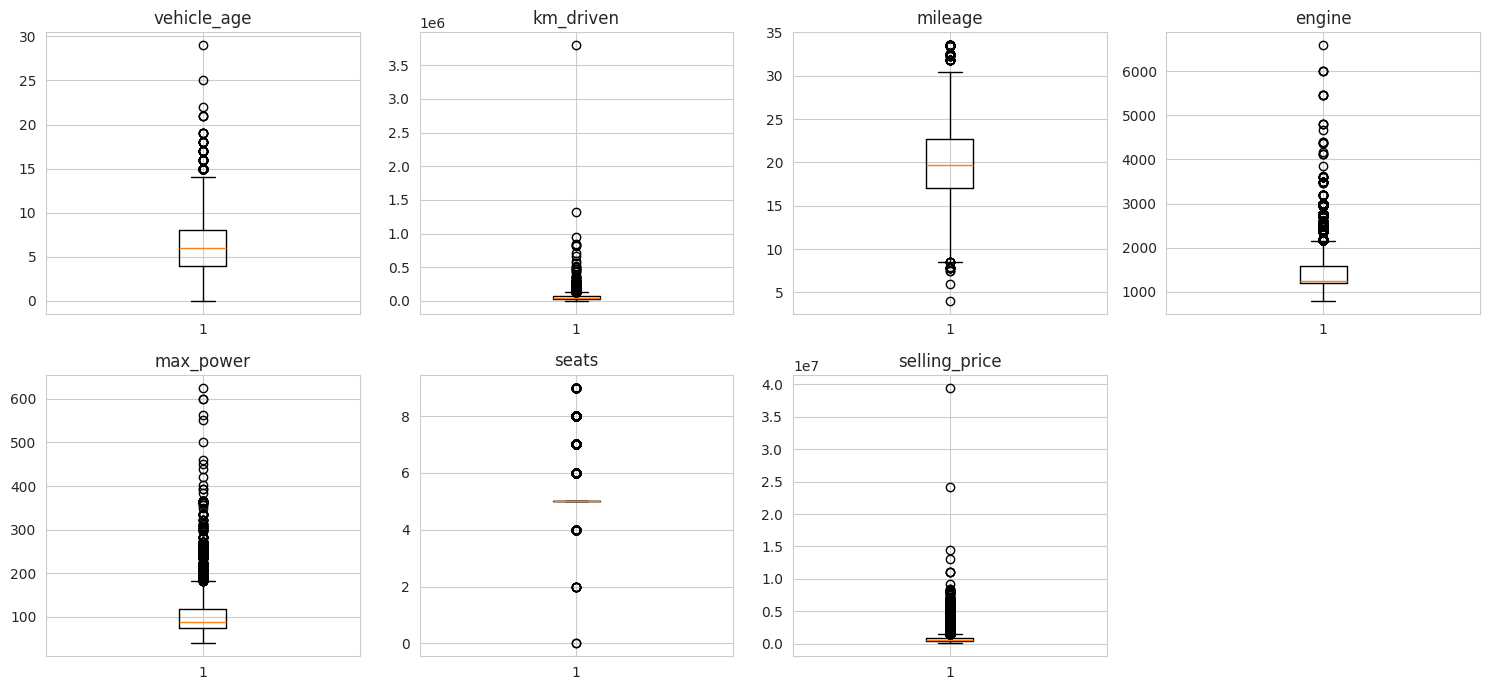

In [7]:
# The numeric columns to inspect for outliers.
numeric_cols = ["vehicle_age", "km_driven", "mileage",
                "engine", "max_power", "seats", "selling_price"]

# Draw one boxplot per numeric column in a 2x4 grid. Each boxplot shows the
# box (interquartile range), the median line, the whiskers (typical range),
# and individual points beyond them (potential outliers).
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, numeric_cols):
    ax.boxplot(df[col])
    ax.set_title(col)
axes.flat[-1].axis("off")   # hide the unused 8th panel (only 7 columns to plot)
plt.tight_layout()
plt.show()


In [8]:
# Non-graphical method: the IQR rule flags anything outside
# [Q1 - 1.5*IQR, Q3 + 1.5*IQR] as a statistical outlier.
outlier_mask = pd.Series(False, index=df.index)   # starts all-False, one flag per row
for col in numeric_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)   # 25th and 75th percentile
    iqr = q3 - q1                                              # interquartile range
    is_out = (df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)
    outlier_mask |= is_out   # a row is flagged if ANY column marks it as an outlier

print(f"IQR flags {outlier_mask.sum()} rows ({outlier_mask.mean()*100:.1f}%) across all columns")

# Blindly dropping every IQR-flagged row would delete a quarter of the data --
# mostly genuine 7-seaters and real premium vehicles, not errors. Instead,
# remove only physically impossible records:
#   - seats <= 0            : a vehicle cannot have zero or negative seats
#   - km_driven > 1,000,000 : an odometer reading above one million km is implausible
before = df.shape[0]
df = df[(df["seats"] > 0) & (df["km_driven"] <= 1_000_000)].reset_index(drop=True)
print(f"Rows removed (physically impossible only): {before - df.shape[0]}")
print("Final shape:", df.shape)


IQR flags 3906 rows (25.6%) across all columns
Rows removed (physically impossible only): 4
Final shape: (15240, 12)


## Interpretation
No missing values were found anywhere in the dataset. 167 duplicate records were removed, a check that only became possible once Unnamed: 0 was dropped, since that leftover index made every row artificially unique.

For outliers, the graphical and non-graphical methods tell complementary stories. The boxplots visually confirm heavy-tailed distributions in km_driven, selling_price, engine and max_power, while the IQR rule quantifies this, flagging 3,906 rows, a quarter of the data. Applying that rule literally would be a mistake: seats has almost no spread (Q1 = Q3 = 5), so IQR flags every legitimate 7-seater as an outlier, and most of the flagged selling_price rows are genuine premium vehicles, not errors. That judgement call is what separates the 4 rows actually removed (0 seats; km_driven > 1,000,000, both physically impossible) from the 3,902 other flagged rows left untouched because they reflect real variation the model should learn from. The dataset now stands at 15,240 clean records across 12 columns, ready for exploratory analysis.

# 8. Data Analysis (EDA)

## Objective
Examine the shape of every numeric and categorical feature, correct skewness, put numeric features on a common scale, encode categoricals, and quantify relationships via a correlation heatmap.

## Why this order matters
The transformation and standardisation steps happen *before* the correlation heatmap. Unlike scaling, a log transform is non-linear, so it can genuinely change a correlation coefficient, not just its scale. Computing the heatmap after transforming means it reflects the true, strongest linear relationships in the data.

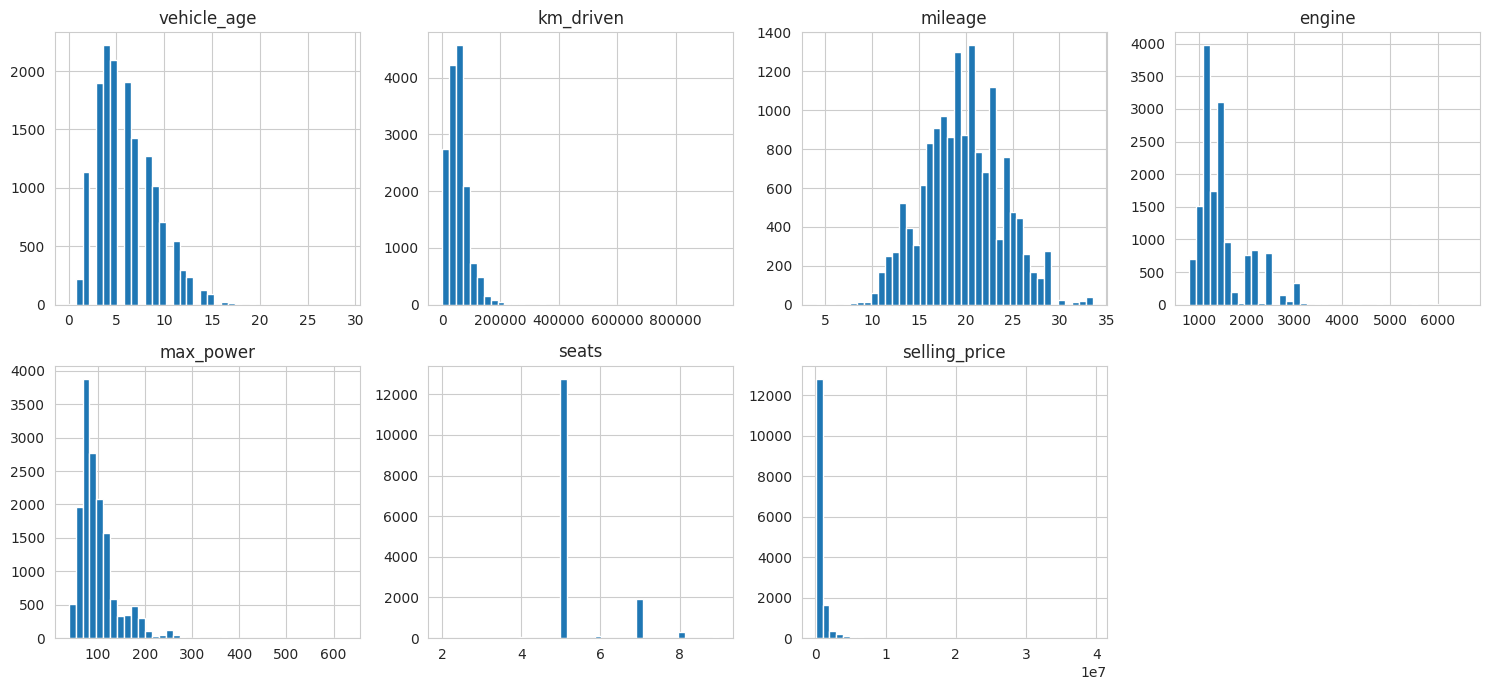

In [9]:
# Plot a histogram for each numeric column. The x-axis is the value range
# (split into 40 bins); the y-axis is the number of vehicles falling into
# each bin, revealing the shape of the distribution (symmetric vs skewed).
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, numeric_cols):
    ax.hist(df[col], bins=40)
    ax.set_title(col)
axes.flat[-1].axis("off")   # hide the unused 8th panel
plt.tight_layout()
plt.show()


In [10]:
# .skew() measures the asymmetry of each distribution:
#   ~0  -> roughly symmetric
#   >0  -> right-skewed (a long tail of high values)
#   <0  -> left-skewed
# Rule of thumb: |skew| > 1 is high, 0.5-1 is moderate, < 0.5 is low.
print(df[numeric_cols].skew().round(2))

# Log-transform the strongly right-skewed continuous columns. np.log1p
# computes log(1 + x); the "1 +" makes it safe even for zero values, unlike
# a plain log() which is undefined at 0.
skewed_cols = ["selling_price", "km_driven", "engine", "max_power"]
for col in skewed_cols:
    df[col] = np.log1p(df[col])

# Re-check skew after the transform to confirm it reduced the asymmetry.
print(df[numeric_cols].skew().round(2))


vehicle_age       0.83
km_driven         5.04
mileage           0.11
engine            1.67
max_power         2.49
seats             2.09
selling_price    10.11
dtype: float64
vehicle_age      0.83
km_driven       -1.06
mileage          0.11
engine           0.70
max_power        0.77
seats            2.09
selling_price    0.57
dtype: float64


In [11]:
# NOTE: this standardisation is computed into a SEPARATE copy of df, not
# applied to df itself. It's shown here (and used for the heatmap just
# below) as an EDA step, but the actual modelling
# pipeline in Section 11 needs its scaler fit on the training split only,
# not the full dataset. Keeping df's numeric columns unscaled at this point
# means Section 10 can split first and scale correctly, with no risk of
# accidentally scaling twice or leaking test rows into an earlier full-data
# fit. (Standardisation does not change correlation values, since it's a linear
# per-column rescaling, so the heatmap below is identical either way.)
numeric_features = ["vehicle_age", "km_driven", "mileage", "engine", "max_power", "seats"]
df_scaled_preview = df.copy()          # a throwaway copy, so df itself stays untouched
preview_scaler = StandardScaler()      # rescales each column to mean 0, std 1: z = (x - mean) / std
df_scaled_preview[numeric_features] = preview_scaler.fit_transform(df_scaled_preview[numeric_features])

# Confirm: every scaled feature should now show mean ~0 and std ~1.
df_scaled_preview[numeric_features].agg(["mean", "std"]).round(2)


,vehicle_age,km_driven,mileage,engine,max_power,seats
mean,-0.0,0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


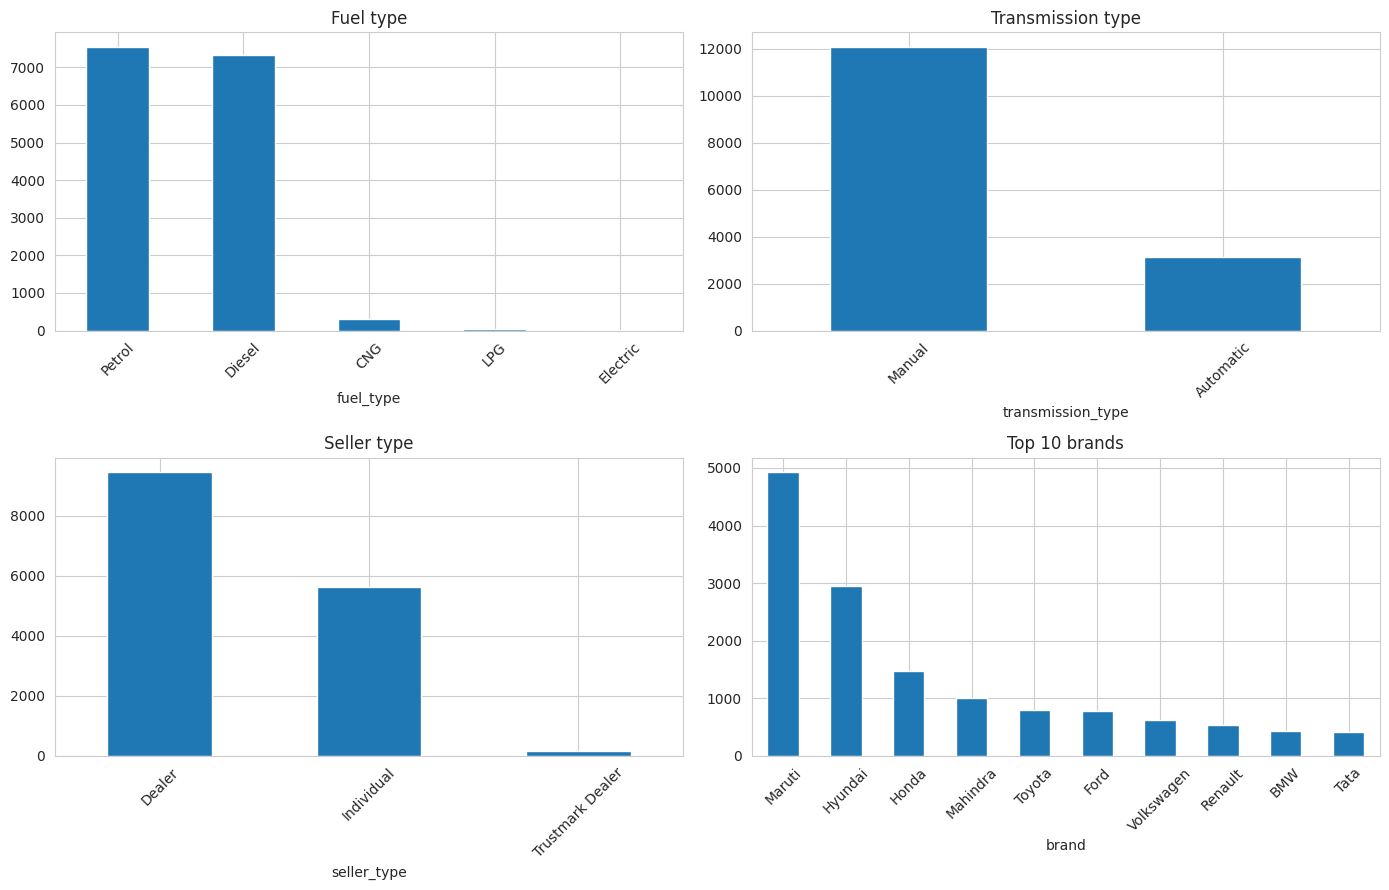

In [12]:
# A bar plot shows the frequency of each category: the height of each bar
# is the number of vehicles in that category. .value_counts() computes the
# counts, and .plot(kind="bar") draws them straight from the resulting Series.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
df["fuel_type"].value_counts().plot(kind="bar", ax=axes[0,0], title="Fuel type")
df["transmission_type"].value_counts().plot(kind="bar", ax=axes[0,1], title="Transmission type")
df["seller_type"].value_counts().plot(kind="bar", ax=axes[1,0], title="Seller type")
df["brand"].value_counts().head(10).plot(kind="bar", ax=axes[1,1], title="Top 10 brands")   # too many brands to show all
for ax in axes.flat:
    ax.tick_params(axis="x", rotation=45)   # rotate labels so they don't overlap
plt.tight_layout()
plt.show()


In [13]:
# 'model' has 120 categories, so one-hot encoding it would add ~119 sparse
# columns for little gain over brand + engine + max_power, which already
# capture most of its pricing information. Drop it to keep the feature set compact.
df = df.drop(columns=["model"])

# One-hot encode the remaining nominal categorical variables. get_dummies()
# creates one 0/1 column per category. drop_first=True removes one category
# per variable to avoid the dummy-variable trap (perfect redundancy among
# the new columns), and dtype=int stores the indicators as 0/1 integers
# rather than True/False.
categorical_cols = ["brand", "fuel_type", "transmission_type", "seller_type"]
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)

print("Shape after encoding:", df.shape)


Shape after encoding: (15240, 45)


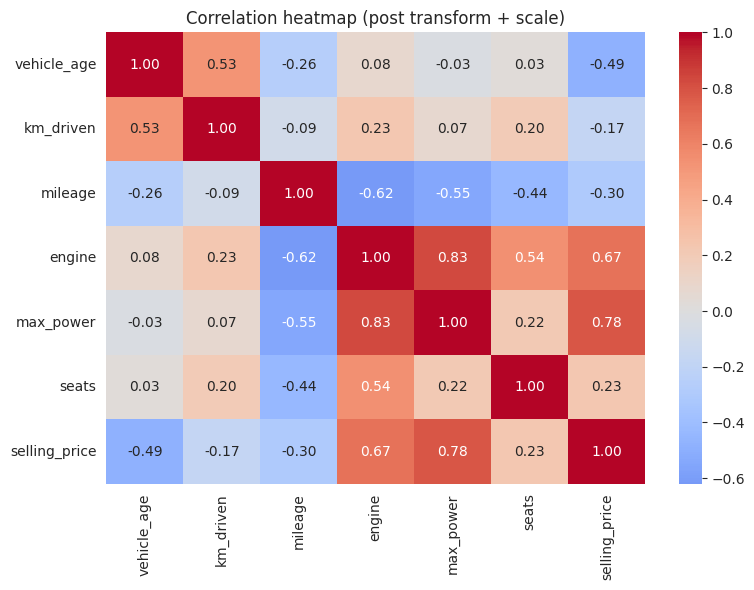

In [14]:
# .corr() computes the pairwise (Pearson) correlation between all numeric
# columns, using the scaled preview copy so the heatmap reflects the
# post-transform, post-scale relationships.
corr = df_scaled_preview[numeric_cols].corr()

# A heatmap colours each correlation: warm = positive, cool = negative.
# annot=True prints the numeric values on top of each cell; center=0 keeps
# 0 (no correlation) at the neutral colour.
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation heatmap (post transform + scale)")
plt.tight_layout()
plt.show()


## Interpretation
The histograms confirmed the same right-skew already visible in Section 6's statistics, most sharply in selling_price, km_driven, engine and max_power. The log transform brought all four down to a mild, workable skew, and standardisation placed every numeric feature on a mean-0, std-1 scale. The bar plots confirmed the market is dominated by petrol/diesel, manual, dealer-sold, Maruti/Hyundai vehicles. Encoding converted the categorical columns to 44 binary indicators, dropping the high-cardinality model column while keeping brand.

The correlation heatmap shows max_power (0.78) and engine (0.67) as by far the strongest predictors of price, with mileage (-0.30), vehicle_age (-0.49) and km_driven (-0.17) negatively related. One figure worth flagging specifically: vehicle_age's correlation here is -0.49, almost double what a raw, untransformed correlation would show (-0.24), because depreciation isn't a straight line, and the log transform straightens it out. The heatmap also flags a redundancy worth carrying into modelling: engine and max_power are themselves correlated at 0.83.

# 9. Feature Selection

## Objective
Use the correlation-with-target result from Section 8 to rank all 44 features, then confirm that ranking with SelectKBest, and settle on a final feature set for modelling.

In [15]:
# Correlation of every feature with the target, then ranked by absolute
# strength (a larger absolute value = a stronger relationship, in either
# direction, positive or negative).
corr_with_target = df.corr()["selling_price"].drop("selling_price")
corr_ranked = corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index)

print(corr_ranked.head(12).round(3))

# Select features whose absolute correlation with the target exceeds 0.10.
selected_by_corr = corr_ranked[corr_ranked.abs() > 0.10].index.tolist()
print("Features with |corr| > 0.10:", len(selected_by_corr))


max_power                   0.781
engine                      0.674
transmission_type_Manual   -0.499
vehicle_age                -0.486
fuel_type_Diesel            0.392
fuel_type_Petrol           -0.360
brand_BMW                   0.334
brand_Maruti               -0.302
mileage                    -0.301
brand_Mercedes-Benz         0.262
brand_Toyota                0.248
seats                       0.231
Name: selling_price, dtype: float64
Features with |corr| > 0.10: 17


In [16]:
# Separate the features (X) from the target (y).
X = df.drop(columns=["selling_price"])
y = df["selling_price"]

# SelectKBest scores each feature with f_regression (an F-statistic for the
# strength of its linear relationship with the target) and keeps the k
# highest-scoring ones. .fit(X, y) computes the scores.
selector = SelectKBest(score_func=f_regression, k=10).fit(X, y)

# View the feature scores, ranked from highest to lowest.
scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
print(scores.head(12).round(1))

# .get_support() returns a True/False mask of which columns were kept;
# X.columns[mask] turns that mask back into the actual column names.
selected_features = X.columns[selector.get_support()].tolist()
print("Final 10 selected features:", selected_features)


max_power                   23802.0
engine                      12712.8
transmission_type_Manual     5039.0
vehicle_age                  4704.4
fuel_type_Diesel             2771.3
fuel_type_Petrol             2262.1
brand_BMW                    1917.2
brand_Maruti                 1532.0
mileage                      1518.1
brand_Mercedes-Benz          1126.9
brand_Toyota                  994.7
seats                         856.5
dtype: float64
Final 10 selected features: ['vehicle_age', 'mileage', 'engine', 'max_power', 'brand_BMW', 'brand_Maruti', 'brand_Mercedes-Benz', 'fuel_type_Diesel', 'fuel_type_Petrol', 'transmission_type_Manual']


## Interpretation
Correlation and SelectKBest agree almost exactly. This is expected, since f_regression's F-statistic for a single feature is mathematically derived from that feature's correlation with the target. What they converge on is a clear story: mechanical capability (max_power, engine) dominates, followed by depreciation and usage (vehicle_age, mileage), configuration (transmission, fuel type), and brand tier (BMW, Mercedes-Benz as premium markers, Maruti as a budget one). max_power and engine are themselves correlated at 0.83, so there's some redundancy in the top two, worth keeping in mind when Section 11 chooses models, since tree-based methods handle that redundancy natively while a plain linear model may need regularisation (Ridge) to manage it. These 10 features are what the rest of the notebook builds on.

# 10. Train/Test Split

## Objective
Split the data into training and test sets *before* fitting the scaler, so the scaler learns its mean/std only from data the model will actually train on, never from data reserved for evaluation.

## Why this has to happen first
Fitting a StandardScaler on the full dataset (as we did in Section 8, purely for EDA) means its mean and standard deviation are influenced by rows that will later be used to *evaluate* the model: leakage. The fix is mechanical: split first, fit the scaler on the training rows only, then use that same fitted scaler to transform the test rows.

One-hot encoding is different: it doesn't estimate anything from the target or the feature distributions, it just maps existing categories to fixed columns. Doing it before the split is safe, and actually necessary here: fuel_type has only 4 Electric-fuel rows in the entire dataset, so splitting first risks all 4 landing in one side and creating a column mismatch between train and test.

In [17]:
# The 10 features Section 9 selected.
X = df[selected_features]
y = df["selling_price"]

# Split BEFORE any scaling: 80% train / 20% test, with a fixed random_state
# so the same split is reproduced every time this cell runs.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

# Of the 10 selected features, only 4 are continuous; the other 6 are already
# 0/1 dummy indicators (brand/fuel/transmission) and don't need scaling.
continuous_cols = ["vehicle_age", "mileage", "engine", "max_power"]

# Fit the scaler on TRAINING data only, then apply that same fit to both
# sets. This prevents information from the test set leaking into training.
scaler = StandardScaler()
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])   # fit AND transform
X_test[continuous_cols] = scaler.transform(X_test[continuous_cols])        # transform ONLY, no re-fit

# Sanity check: train should be exactly mean 0 / std 1 (it defined the
# scaling); test should be CLOSE but not exact, since it's scaled using
# training statistics rather than its own.
print(X_train[continuous_cols].agg(["mean", "std"]).round(2))
print(X_test[continuous_cols].agg(["mean", "std"]).round(2))


X_train: (12192, 10) | X_test: (3048, 10)
      vehicle_age  mileage  engine  max_power
mean          0.0     -0.0    -0.0        0.0
std           1.0      1.0     1.0        1.0
      vehicle_age  mileage  engine  max_power
mean         0.01     0.03   -0.00      -0.01
std          0.99     1.01    0.99       0.98


## Interpretation
The 15,240 records split into 12,192 for training and 3,048 for testing. The key check is in the last two outputs: the training set's continuous features land at exactly mean 0 and std 1, because the scaler was fit on exactly that data, but the test set lands only approximately there. That small gap is the whole point: if the test set had also come out at exactly 0/1, it would mean the scaler had been fit on it too, and any model evaluated on it later would look better than it actually is. Every model below trains only on X_train/y_train; X_test/y_test stay untouched until Section 12's evaluation.

# 11. Model Selection and Training

## Model 1: Ridge Regression

## Objective
Train a Ridge Regression as the first of three models, tuning its regularisation strength (alpha) via cross-validated grid search on the training set only.

## Why Ridge, and why first
Ridge is ordinary linear regression with an added penalty on large coefficients, which makes it more stable than plain linear regression when predictors are correlated with each other, directly relevant here, since Section 8 found engine and max_power correlated at 0.83. It's also the most interpretable of the three models we'll try, making it the natural baseline the other two get compared against.

In [18]:
# Search across a range of regularisation strengths. Small alpha = closer to
# plain linear regression; large alpha = more shrinkage on the coefficients.
param_grid = {"alpha": [0.01, 0.1, 1, 5, 10, 50, 100]}

# GridSearchCV tries every alpha in param_grid, with 5-fold cross-validation
# on the training data, and scores each using negative MSE (sklearn expects
# a "higher is better" score, so error metrics are negated internally).
ridge_grid = GridSearchCV(
    Ridge(), param_grid, cv=5, scoring="neg_mean_squared_error", n_jobs=-1
)
ridge_grid.fit(X_train, y_train)   # tuning uses ONLY training data, via internal CV folds

print("Best alpha:", ridge_grid.best_params_)
# The score is negative MSE, so negate it back and take the square root to
# report RMSE, in the same log-space units the model was trained on.
print("Best CV RMSE (log-space):", round((-ridge_grid.best_score_) ** 0.5, 4))

# .best_estimator_ is the Ridge model refit on the full training set using
# the best alpha found. .coef_ holds one coefficient per feature; sorting by
# absolute value shows which features influence price the most, regardless
# of the direction of that influence.
best_ridge = ridge_grid.best_estimator_
coefs = pd.Series(best_ridge.coef_, index=X_train.columns).sort_values(key=abs, ascending=False)
print(coefs.round(3))


Best alpha: {'alpha': 1}
Best CV RMSE (log-space): 0.2439
vehicle_age                -0.346
brand_BMW                   0.321
max_power                   0.321
brand_Mercedes-Benz         0.267
transmission_type_Manual   -0.183
brand_Maruti                0.142
engine                      0.131
fuel_type_Petrol           -0.111
fuel_type_Diesel            0.078
mileage                    -0.046
dtype: float64


## Interpretation
GridSearchCV chose alpha = 1, fairly light regularisation. That's informative on its own: it suggests the multicollinearity between engine and max_power isn't severe enough to force heavy shrinkage, though a small penalty still helps stabilise the coefficients.

Most coefficients match what Sections 8 and 9 predicted: vehicle_age is the strongest effect and negative (depreciation), max_power is strongly positive, transmission_type_Manual is negative (manual cars sell for less), and BMW/Mercedes-Benz are strongly positive, confirming the luxury-brand premium.

One result needs unpacking: brand_Maruti comes out positive, even though Maruti's raw correlation with price was negative and its actual average price sits well below the dataset average. The explanation is in how one-hot encoding works with drop_first=True: every brand coefficient is measured relative to Audi specifically, the alphabetically-first brand that got dropped as the reference category, and Audi is itself a premium outlier in this data. Once engine, power, age and mileage already control for "how big and powerful the car is," the remaining Maruti coefficient reflects a comparison against a mostly-hypothetical small-engined Audi that doesn't really exist in the dataset. It's a reminder that individual one-hot coefficients should always be read against their specific reference category.

The cross-validated RMSE is measured in log-space and on training folds only, useful as a sanity check, not yet the final answer. Section 12 evaluates this model (and the other two) on the untouched test set, translated back into actual Rupees.

## Model 2: Random Forest Regressor

## Objective
Train a Random Forest, an ensemble of decision trees, as the second model, tuning its key hyperparameters via cross-validated randomised search on the training set.

## Why Random Forest
Unlike Ridge, Random Forest doesn't assume a linear relationship and doesn't need engine and max_power's collinearity managed through a penalty term; each tree can simply split on whichever of the two is more useful at that point. It should also pick up any non-linear effects Ridge can't represent.

## Note on search strategy
A full grid search over 4 hyperparameters is very slow given the number of trees involved. RandomizedSearchCV samples a fixed number of combinations instead of testing every one, trading a small amount of thoroughness for a search that completes in a reasonable time.

In [19]:
# The hyperparameters to search over:
#   n_estimators     : number of trees in the forest
#   max_depth        : how deep each tree can grow (None = unlimited)
#   min_samples_leaf : minimum samples required at a leaf node (higher = simpler trees)
#   max_features     : how many features each split considers ("sqrt" or all)
param_dist = {
    "n_estimators": [50, 100, 150],
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", None],
}

# RandomizedSearchCV samples n_iter=10 random combinations from param_dist
# instead of trying all of them (faster than GridSearchCV for larger grids),
# using 3-fold cross-validation on the training data.
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42), param_dist, n_iter=10, cv=3,
    scoring="neg_mean_squared_error", n_jobs=-1, random_state=42
)
rf_search.fit(X_train, y_train)

print("Best params:", rf_search.best_params_)
print("Best CV RMSE (log-space):", round((-rf_search.best_score_) ** 0.5, 4))

# .best_estimator_ is the tuned Random Forest. .feature_importances_ gives
# each feature's share of the total reduction in prediction error the forest
# achieves by splitting on it, so higher = more influential.
best_rf = rf_search.best_estimator_
importances = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances.round(3))


Best params: {'n_estimators': 150, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 20}
Best CV RMSE (log-space): 0.182
max_power                   0.662
vehicle_age                 0.241
engine                      0.056
mileage                     0.026
fuel_type_Diesel            0.005
transmission_type_Manual    0.004
brand_Maruti                0.002
brand_Mercedes-Benz         0.001
fuel_type_Petrol            0.001
brand_BMW                   0.000
dtype: float64


## Interpretation
The tuned Random Forest's cross-validated RMSE is noticeably lower than Ridge's at this training stage, an early signal the non-linear model fits this data better, though Section 12 will confirm that properly on the held-out test set.

The feature importances tell a much more concentrated story than Ridge's coefficients: max_power and vehicle_age alone account for about 90% of the model's importance, with engine, mileage and everything else trailing far behind; brand and fuel indicators are essentially at zero. This doesn't mean brand and fuel type don't matter; two things are happening. First, engine and max_power are correlated at 0.83, and trees only need one of a pair of redundant features to make a good split, so whichever gets picked first claims most of the credit. Second, scikit-learn's default impurity-based importance favours continuous, high-cardinality features over binary 0/1 indicators, simply because continuous features offer more possible split points, not necessarily because the binary features carry less real signal. Ridge's coefficients, which gave BMW and Mercedes-Benz real weight, are a useful counterbalance to keep in mind here.

## Model 3: Gradient Boosting Regressor

## Objective
Train a Gradient Boosting model, trees built sequentially, each one correcting the errors of the ones before it, as the third model, tuning learning rate, tree depth, number of estimators and subsampling rate.

## Why Gradient Boosting
Where Random Forest builds many independent trees and averages them, Gradient Boosting builds trees one at a time, each specifically targeting the previous ensemble's mistakes. This usually gets more accuracy out of the same features, at the cost of being slower to train and more sensitive to its hyperparameters.

In [20]:
# The hyperparameters to search over:
#   n_estimators  : number of boosting stages (trees added sequentially)
#   learning_rate : how much each new tree corrects the previous ones (smaller = slower, steadier learning)
#   max_depth     : depth of each individual tree
#   subsample     : fraction of training rows each tree sees (< 1.0 adds randomness, reduces overfitting)
param_dist = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.7, 0.85, 1.0],
}

# Same randomised, cross-validated search approach as the Random Forest,
# but with n_iter=12 samples this time, given the larger parameter space.
gb_search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=42), param_dist, n_iter=12, cv=3,
    scoring="neg_mean_squared_error", n_jobs=-1, random_state=42
)
gb_search.fit(X_train, y_train)

print("Best params:", gb_search.best_params_)
print("Best CV RMSE (log-space):", round((-gb_search.best_score_) ** 0.5, 4))

# Same idea as the Random Forest above: .feature_importances_ ranks each
# feature by how much it reduced prediction error across the boosted trees.
best_gb = gb_search.best_estimator_
importances = pd.Series(best_gb.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances.round(3))


Best params: {'subsample': 0.85, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.1}
Best CV RMSE (log-space): 0.178
max_power                   0.590
vehicle_age                 0.266
engine                      0.097
mileage                     0.021
transmission_type_Manual    0.017
fuel_type_Diesel            0.004
fuel_type_Petrol            0.003
brand_Mercedes-Benz         0.002
brand_Maruti                0.001
brand_BMW                   0.000
dtype: float64


## Interpretation
The tuned model uses a moderate learning rate (0.1), fairly deep trees for boosting, 300 of them, and subsample = 0.85, meaning each tree trains on 85% of the training data, sampled fresh each round. That subsampling is a form of regularisation, and the fact that search preferred 0.85 over using all the data suggests a small amount of that regularisation genuinely helped.

Its CV RMSE is the best of the three models so far, edging out Random Forest and clearly ahead of Ridge, though this is still training-time cross-validation, not the held-out test set.

The feature importance pattern echoes Random Forest's: max_power and vehicle_age dominate, engine and mileage trail behind, and the brand/fuel indicators are near zero, for the same two reasons discussed under Model 2. One small difference: engine and transmission_type_Manual pick up a little more credit here than in Random Forest, a reminder that "feature importance" isn't a fixed property of the data, it's specific to how each individual model happened to use it.

## Section 11 Summary: Observations and Conclusions

All three models were tuned using cross-validation on the training set only; X_test has not been touched by any of this. The cross-validated RMSE (log-space) ranks Gradient Boosting marginally ahead of Random Forest, with both well ahead of Ridge. This is an early, training-side signal that the non-linear models capture something in this data a linear model can't, most plausibly the strong redundancy between engine and max_power, and any non-linear depreciation effects. Section 12 confirms this properly on the untouched test set, with metrics translated back into real Rupees.

# 12. Model Evaluation

## Objective
Evaluate all three trained models on the untouched test set using RMSE, MAE and R², computed both in log-space and back-transformed to actual Rupees, then compare and select the best-performing model.

## Why both scales
Every model was trained to predict log(selling_price), so log-space metrics are the fairest like-for-like comparison of what each model actually optimised. But nobody making a pricing decision thinks in log-Rupees, so every metric is also translated back via np.expm1 (the inverse of log1p) into real Rupees, which is what actually matters for Section 13's web app.

In [21]:
# np.expm1 is the exact inverse of the np.log1p transform applied earlier,
# so this converts the true test-set prices back from log-space into actual
# Rupees. Computed once here, then reused for every model below.
y_test_rupees = np.expm1(y_test)

results = []
for name, model in [("Ridge", best_ridge), ("Random Forest", best_rf), ("Gradient Boosting", best_gb)]:
    pred_log = model.predict(X_test)       # prediction in log-space (what the model was trained on)
    pred_rupees = np.expm1(pred_log)       # back-transform this model's predictions to Rupees

    # Compute RMSE (root mean squared error), MAE (mean absolute error) and
    # R2 (proportion of variance explained), in BOTH spaces: log-space
    # (comparable to the CV scores above) and actual Rupees (comparable to
    # real-world prices).
    results.append({
        "Model": name,
        "RMSE_log": mean_squared_error(y_test, pred_log) ** 0.5,
        "MAE_log": mean_absolute_error(y_test, pred_log),
        "R2_log": r2_score(y_test, pred_log),
        "RMSE_Rupees": mean_squared_error(y_test_rupees, pred_rupees) ** 0.5,
        "MAE_Rupees": mean_absolute_error(y_test_rupees, pred_rupees),
        "R2_Rupees": r2_score(y_test_rupees, pred_rupees),
    })

# Collect all three models' metrics into one table for side-by-side comparison.
results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))


            Model  RMSE_log  MAE_log  R2_log  RMSE_Rupees  MAE_Rupees  R2_Rupees
            Ridge    0.2445   0.1865  0.8721  715464.2316 168016.3339     0.6037
    Random Forest    0.1850   0.1341  0.9268  633853.2227 113537.6069     0.6890
Gradient Boosting    0.1827   0.1344  0.9286  644857.2763 113448.8037     0.6781


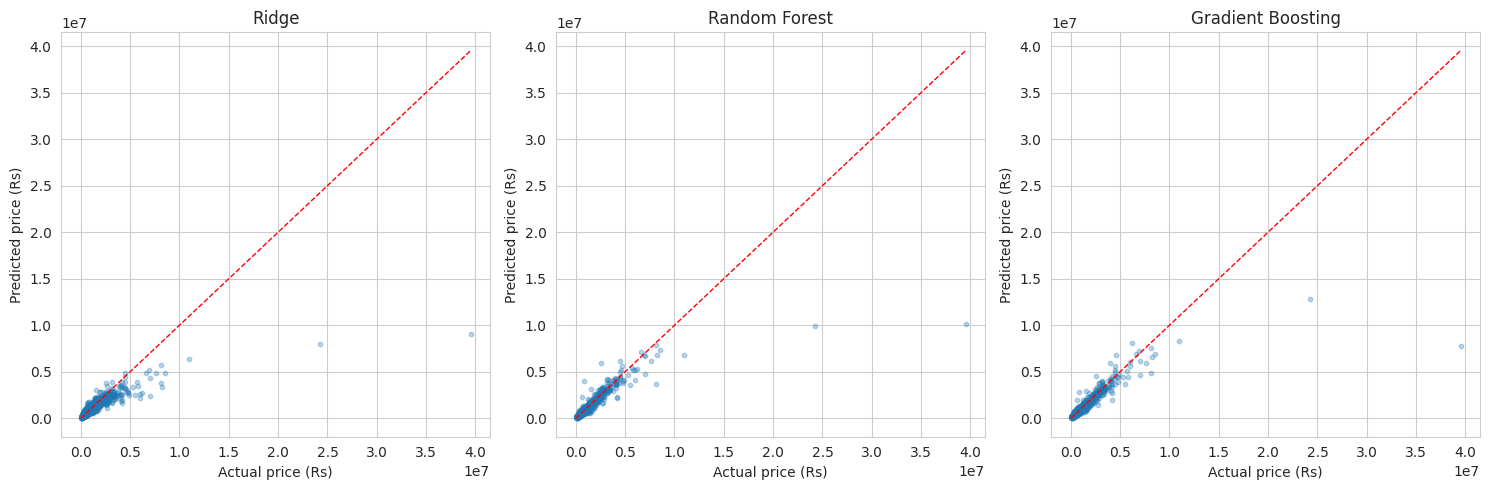

In [22]:
# For each model, plot predicted vs actual price (in Rupees) on the test
# set. Points close to the diagonal line are accurate predictions; points
# far from it are large errors.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, model) in zip(axes, [("Ridge", best_ridge), ("Random Forest", best_rf), ("Gradient Boosting", best_gb)]):
    pred_rupees = np.expm1(model.predict(X_test))
    ax.scatter(y_test_rupees, pred_rupees, alpha=0.3, s=10)   # alpha=0.3 shows overlapping points as denser
    lims = [0, y_test_rupees.max()]
    ax.plot(lims, lims, "r--", linewidth=1)   # perfect-prediction reference line (predicted == actual)
    ax.set_title(name)
    ax.set_xlabel("Actual price (Rs)")
    ax.set_ylabel("Predicted price (Rs)")
plt.tight_layout()
plt.show()


In [23]:
# Look at the individual test rows where each tree model's Rupee-scale error
# was largest, to see why Gradient Boosting's Rupee RMSE came out slightly
# worse despite having the better log-space score.
for name, model in [("Random Forest", best_rf), ("Gradient Boosting", best_gb)]:
    pred_rupees = np.expm1(model.predict(X_test))
    abs_err = np.abs(pred_rupees - y_test_rupees.values)
    # np.argsort sorts row indices from smallest to largest error; [-5:]
    # takes the 5 largest, and [::-1] reverses so the biggest error prints first.
    top5_idx = np.argsort(abs_err)[-5:][::-1]
    print(f"--- {name}: 5 largest absolute errors ---")
    for i in top5_idx:
        print(f"  actual=Rs{y_test_rupees.values[i]:,.0f}  predicted=Rs{pred_rupees[i]:,.0f}  error=Rs{abs_err[i]:,.0f}")


--- Random Forest: 5 largest absolute errors ---
  actual=Rs39,500,000  predicted=Rs10,098,714  error=Rs29,401,286
  actual=Rs24,200,000  predicted=Rs9,901,521  error=Rs14,298,479
  actual=Rs8,100,000  predicted=Rs3,655,925  error=Rs4,444,075
  actual=Rs11,000,000  predicted=Rs6,760,308  error=Rs4,239,692
  actual=Rs2,600,000  predicted=Rs5,893,650  error=Rs3,293,650
--- Gradient Boosting: 5 largest absolute errors ---
  actual=Rs39,500,000  predicted=Rs7,777,449  error=Rs31,722,551
  actual=Rs24,200,000  predicted=Rs12,828,100  error=Rs11,371,900
  actual=Rs8,100,000  predicted=Rs4,827,693  error=Rs3,272,307
  actual=Rs11,000,000  predicted=Rs8,309,143  error=Rs2,690,857
  actual=Rs7,000,000  predicted=Rs4,642,429  error=Rs2,357,571


## Interpretation
Ridge is clearly the weakest model on every single metric, in both spaces, confirming Section 11's early signal that this data has non-linear structure a purely linear model can't capture.

Between Random Forest and Gradient Boosting, the picture is genuinely mixed. In log-space, the space both models were trained on, Gradient Boosting is marginally ahead. But once predictions are translated back into actual Rupees, the ranking flips: Random Forest has the lower RMSE and higher R², while MAE in Rupees is close enough to call a tie. Since RMSE penalises large errors more heavily than MAE, and it's specifically the Rupee-scale RMSE that flips, the difference comes down to how each model handles the very largest prices in the data.

Checking the actual top errors confirms this. Both models' worst single miss is the same ₹39,500,000 vehicle flagged all the way back in Section 7's cleaning, the one deliberately kept rather than stripped out via the IQR rule, because it was genuine data, not an error. Gradient Boosting misses it by a wider margin than Random Forest does, and that one vehicle, essentially unrepresented anywhere else in the training data, is largely what drives Gradient Boosting's Rupee-RMSE above Random Forest's, even though Gradient Boosting is the better all-round fit in log-space.

Given this project's stated aim of supporting real pricing decisions, the practically-relevant scale is Rupees, not log-Rupees. On that basis, **Random Forest is selected as the best-performing model**: lower Rupee RMSE, higher Rupee R², and an MAE effectively tied with Gradient Boosting's. Gradient Boosting remains a very close second. Ridge, while the weakest of the three, remains useful as an interpretable benchmark; its coefficients (Section 11) explained *why* prices move, in a way the other two can't.

# 13. Model Deployment with Web App

## Objective
Save everything the deployed app will need (the trained model, the fitted scaler, and which columns require which preprocessing steps) into a single file, so a separate Streamlit app (app.py, not a notebook cell) can load it and reproduce the exact same pipeline used during training.

## Why bundle everything together, not just the model
A trained model on its own is not enough to safely predict on new, raw input. It expects data that has already been through the same steps as the training data: engine and max_power log-transformed, all four continuous columns scaled using the SAME mean/std learned from X_train. Bundling the model, the scaler, and a record of which columns need which transform removes any chance of a silent mismatch.

In [24]:
# Bundle the trained model, the fitted scaler, and the exact preprocessing
# steps required, as one dictionary saved to one file, so app.py only has
# to load a single artifact and cannot accidentally use a mismatched scaler.
bundle = {
    "model": best_rf,                                  # the Random Forest selected in Section 12
    "scaler": scaler,                                   # fitted on X_train ONLY (Section 10)
    "selected_features": selected_features,              # the 10 features, IN ORDER
    "continuous_cols": continuous_cols,                  # ['vehicle_age','mileage','engine','max_power']
    "log_transform_cols": ["engine", "max_power"],        # subset that ALSO need log1p, BEFORE scaling
}

os.makedirs("model", exist_ok=True)                       # create the output folder if it doesn't exist yet
joblib.dump(bundle, "model/car_price_model_bundle.pkl", compress=3)    # serialise the whole bundle to a single file

print("Saved model/car_price_model_bundle.pkl")


Saved model/car_price_model_bundle.pkl


## Interpretation
This is the last technical cell of the notebook, and its output, car_price_model_bundle.pkl, is the bridge to the Streamlit app, which is a separate app.py file, not another notebook cell. Streamlit apps run through a terminal command (streamlit run app.py) and render in a browser; they don't execute inside a notebook the way pandas or sklearn code does. Everything the app needs to turn a raw, human-entered car description into a price prediction is now in one file: the model, the scaler, and, critically, the record of exactly which columns need log1p before scaling. Missing that last detail is a common, silent deployment bug: the model would still produce a number, it just wouldn't be the right one.

The app itself (app.py) presents a form for vehicle age, mileage, engine size, power, brand, fuel type and transmission, applies this exact preprocessing pipeline to whatever the user enters, and returns a predicted price in Rupees. Because only 3 brands and 2 fuel types survived feature selection, the app deliberately limits those dropdowns to the categories the model can actually distinguish, plus an honest "Other" option, rather than offering a full list that would silently collapse to the same prediction for most choices.

# 14. Conclusion

This project carried a used-vehicle dataset through the full data science lifecycle: from raw CSV to a deployed, interactive price-prediction tool. Starting from 15,411 records, cleaning removed 167 duplicates and 4 physically impossible entries, leaving 15,240 records across 12 meaningful columns. Exploratory analysis found strong right-skew in several variables and identified mechanical capability as the dominant influence on price, a finding confirmed both by correlation analysis and SelectKBest, which converged independently on the same 10 features: max_power, engine, vehicle_age, mileage, transmission type, fuel type, and three brand indicators.

Three regression models were trained on those 10 features, each tuned via cross-validation on the training set only: Ridge Regression, Random Forest, and Gradient Boosting. Evaluated on a held-out test set of 3,048 vehicles never seen during training or tuning, Ridge was clearly the weakest, confirming that this dataset has non-linear structure a purely linear model can't fully capture. Random Forest and Gradient Boosting performed close to each other, with Random Forest selected as the best model on the practically-relevant Rupee scale, while Gradient Boosting technically fit better in the log-space the models were trained on. Both models' single largest error was on the same ₹39.5 million vehicle flagged as a legitimate outlier all the way back in the cleaning stage, a direct, visible link between an early data-quality decision and a late-stage model limitation.

The selected model was integrated into an interactive Streamlit web application, where a user can enter a vehicle's age, mileage, engine size, power, brand, fuel type and transmission, and receive an estimated selling price. The app is deliberately honest about the model's real boundaries: since only 3 brands and 2 fuel types survived feature selection, every other value is presented through an explicit "Other" option rather than a misleading illusion of full coverage. Taken as a whole, the project demonstrates that a small, interpretable set of features, dominated by engine power and size, with age, usage, configuration and brand tier playing supporting roles, can explain a substantial share of used-vehicle pricing, and that the gap between "a model that fits well" and "a model that's honest about what it doesn't know" is as much a design choice as a technical one.

# 15. Recommendations

Based on the results of this project, the following recommendations are made.

**On model choice.** Random Forest is recommended as the production model on the strength of its Rupee-scale accuracy, but Gradient Boosting is close enough that it's worth revisiting with a wider hyperparameter search; this project used RandomizedSearchCV with a modest number of iterations for runtime reasons, and a more exhaustive search may close or reverse the gap. A stacked or averaged ensemble of the two is also a natural next experiment, since they make different kinds of errors on the same data.

**On the extreme-value problem.** Both tree-based models' worst error was on the same ₹39.5 million vehicle, a genuine but extreme data point with no close neighbours in the training set for the model to learn from. Rather than removing such vehicles (which Section 7 deliberately chose not to do), a targeted next step would be either a separate valuation path for luxury vehicles above a price threshold, or explicitly evaluating and reporting model performance separately for standard and premium price segments.

**On feature selection.** The correlation and SelectKBest methods agreed closely, but both measure only linear relationships and were computed once on the full dataset rather than validated across folds. A tree-based importance ranking (with permutation importance rather than the default impurity-based score, which Section 11 found biased toward continuous features) or a wrapper method could surface non-linear feature relevance that was missed.

**On brand and fuel-type coverage.** Only 3 of 32 brands and 2 of 5 fuel types are individually represented in the final model, which the Streamlit app now handles honestly via an "Other" option, but that's a limitation worth removing rather than just labelling. Target encoding (replacing each brand with a statistic like its mean price) would let the model use information from all 32 brands without the sparse-column problem that ruled out one-hot encoding the model column entirely.

**On deployment.** The current app runs locally via streamlit run app.py. Hosting it on Streamlit Community Cloud would make it accessible without a local environment running, and logging each prediction would build a record for monitoring whether the model's accuracy holds up on genuinely new listings.

# 16. References

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451

Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (2nd ed.). O'Reilly Media.

Han, J., Kamber, M., & Pei, J. (2011). *Data mining: Concepts and techniques* (3rd ed.). Morgan Kaufmann.

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature, 585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). *An introduction to statistical learning: With applications in R*. Springer. https://doi.org/10.1007/978-1-4614-7138-7

Kuhn, M., & Johnson, K. (2013). *Applied predictive modeling*. Springer. https://doi.org/10.1007/978-1-4614-6849-3

McKinney, W. (2010). Data structures for statistical computing in Python. In S. van der Walt & J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 56–61). https://doi.org/10.25080/Majora-92bf1922-00a

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Streamlit Inc. (2024). *Streamlit documentation*. https://docs.streamlit.io

Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.

Van Rossum, G., & Drake, F. L. (2009). *Python 3 reference manual*. CreateSpace.

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021